In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/24/2022
# version ='1.0'

# Demo: Further Experiments on Solving SOCP by Barrier Method

In book-convex-2004, the barrier method was used to solve the SOCP problem as the following,

\begin{equation}
\label{eq:NL50-socp}
\begin{array}{rll}
\text{minimize} & f^Tx \\
\text{subject to} & \left(\begin{array}{cc}
A_ix+b_i \\
c_i^Tx+d_i
\end{array} \right) \succeq_K 0 & i=1,2,...,m
\end{array}
\end{equation}

where $A_i \in R^{p\times n}$, $b_i\in R^{p}$, $x\in R^n$, and $K$ is the generalized inequality in the norm cone for the Euclidean norm, i.e., the second-order cone.
$$
K=\{(x,t)\in R^{n+1}|\|x\|_2\leq t\}
$$
where it is a self dual cone, i.e. $K^*=K$

Its Lagrange dual function is
$$
L(x, w, z) = f^Tx - \displaystyle{\sum_{i=1}^m}\left(\begin{array}{c}
z_i \\
w_i \\
\end{array} \right)^T \left(\begin{array}{cc}
A_ix+b_i \\
c_i^Tx+d_i
\end{array} \right)
$$
where $\left(\begin{array}{c}
z_i \\
w_i \\
\end{array} \right) \in K^*=K$ 

The optimality conditions are
$$
\begin{array}{rcl}
\nabla_x L = 0 & \Rightarrow & f=\displaystyle{\sum_{i=1}^m}A_i^Tz_i+w_ic_i \\
\left(\begin{array}{c}
z_i \\
w_i \\
\end{array} \right)^T \left(\begin{array}{cc}
A_ix+b_i \\
c_i^Tx+d_i
\end{array} \right) = 0 & \Rightarrow & \left(\begin{array}{c}
z_i \\
w_i \\
\end{array} \right) = 0 \text{ or } \left(\begin{array}{cc}
A_ix+b_i \\
c_i^Tx+d_i
\end{array} \right) = 0,i=1,2,...,m \\
& & \left(\begin{array}{cc}
A_ix+b_i \\
c_i^Tx+d_i
\end{array} \right) \in K \\
& & \left(\begin{array}{c}
z_i \\
w_i \\
\end{array} \right) \in K^*=K \\
\end{array}
$$

The procedure to generate the problem parameters, $A, b, c, d$, with optimal value of $p^*=1$ is listed in the Algorithm [\ref{alg:NL50-cap}].


### Procedure to generate parameters $A, b, c, d$ with optimal value of $p^*=1$

1. Determine $k$ among $m$ inequality constraints to be active, $k<m$, in practice, $k$ can be equal to $ceil(n/(p+1))$ (will be explained later)
1. Randomly generate $x^* \in \mathbf{N}(0,1)^n$ (i.e. normal distribution)
1. For $i=1,2,...,k$, select $A_i, b_i, c_i, d_i$ to satisfy
$$
A_ix^*+b_i = c_i^Tx^*+d_i=0
$$
1. For $i=1,2,...,k$, randomly generate $(z_i, w_i)\in K^*=K$
1. For $i=k,k+1,...,n$, randomly generate $A_i, b_i, c_i, d_i$ to satisfy
$$
(A_ix^*+b_i, c_i^Tx^*+d_i) \in K
$$
1. For $i=k,k+1,...,n$, set $(z_i, w_i)=0$
1. let $f=\displaystyle{\sum_{i=1}^m}A_i^Tz_i+w_ic_i$
1. let $s=f^Tx^*$, if $s<0$, repeat the above steps to regenerate $A, b, c, d, w, z$ until $s>0$
1. scale $z, w$ and $f$, so that $f^Tx^*=p^*=1$


The start point of the barrier method can be attained by solving the phase I feasibility problem,
$$
\begin{array}{rl}
\text{minimize} & s \\
\text{subject to} & \|A_ix+b_i\|_2 \leq s + (c_i^Tx+d_i) \\
\end{array}
$$
which is also a SOCP problem, with 
$$
\begin{array}{rcl}
\hat{A}_i & = & \left[A_i, \mathbf{1}_{p\times 1} \right] \\
\hat{b}_i & = & b_i \\
\hat{c}_i & = & \left[c_i, 1 \right] \\
\hat{d}_i & = & d_i \\
\end{array}
$$

The corresponding dual problem is

$$
\begin{array}{rcl}
\text{maximize} & \displaystyle{\sum_{i=1}^{m}\hat{b}_i^T\hat{z}_i+\hat{d}_i\hat{w}_i} \\
\text{subject to} & \displaystyle{\sum_{i=1}^{m}}(\hat{A}_i^T\hat{z}_i+\hat{c}_i\hat{w}_i) = f \\
& \parallel \hat{z}_i \parallel_2 \leq \hat{w}_i & i=1,2,...,m \\
\end{array}
$$

Hence, in solving the phase I feasibility problem via barrier method, it follows that (refer to Example 11.8 in the textbook), the point on the central path,
$$
\begin{array}{cc}
\hat{z}_i^*(t)=-\dfrac{2}{t\hat\alpha_i}(\hat{A}_i\hat{x}^*(t)+\hat{b}_i) & \hat{w}_i^*=\dfrac{2}{t\hat\alpha_i}(\hat{c}_i^T\hat{x}^*(t)+\hat{d}_i) \\
\end{array}
$$

where $\hat\alpha_i=(\hat{c}_i^T\hat{x}^*(t)+\hat{d}_i)^2-\parallel \hat{A}_i\hat{x}^*(t)+\hat{b}_i \parallel_2^2$ is strictly dual feasible, and it can be used to detect infeasibility in solving the Phase I feasibility problem.

The following explains why to select $k=ceil(n/(p+1))$.

In the barrier method solving the SOCP problem in Equ. [\ref{eq:NL50-socp}], the corresponding logarithmic barrier function is
$$
\begin{array}{rcl}
\phi(x) & = & -\displaystyle{\sum_{i=1}^m}\log((c_i^Tx+d_i)^2-\|A_ix+b_i\|_2^2) \\
\end{array}
$$

The gradient and hessian of $\phi(x)$ can be calculated accordingly.
$$
\begin{array}{rcl}
\nabla \phi(x) & = & -\displaystyle{\sum_{i=1}^m} -\dfrac{2(c_i^Tx+d_i)c_i-2A_i^T(A_ix+b_i)}{(c_i^Tx+d_i)^2-\|Ax_i+b_i\|^2} \\
\nabla^2 \phi(x) & = & -\nabla \displaystyle{\sum_{i=1}^m}\dfrac{2(c_i^Tx+d_i)c_i-2A_i^T(A_ix+b_i)}{(c_i^Tx+d_i)^2-\|Ax_i+b_i\|^2} = -(\nabla^2_{part 1} + \nabla^2_{part 2})
\end{array}
$$
where
$$
\begin{array}{rcl}
\nabla^2_{part 1} & = & \displaystyle{\sum_{i=1}^m}\dfrac{2c_ic_i^T-2A_i^TA_i}{(c_i^Tx+d_i)^2-\|A_ix+b_i\|^2} \\
\nabla^2_{part 2} & = & -\displaystyle{\sum_{i=1}^m}\dfrac{4((c_i^Tx+d_i)c_i-A_i^T(A_ix+b_i))((c_i^Tx+d_i)c_i-A_i^T(A_ix+b_i))^T}{((c_i^Tx+d_i)^2-\|A_ix+b_i\|^2)^2}
\end{array}
$$

In the $\nabla^2_{part 1}$, for those $k$ active inequality constraints, $c_i^Tx+d_i\rightarrow 0$ and $\|Ax_i+b_i\|\rightarrow 0$, each of which contributes $p+1$ dimension (remember that $A_i\in R^{p\times n}$, and $c_ic_i^T$ is an addition dimension), so there will be $k\times (p+1)$ dominant vectors. To make $\nabla^2_{part 1}$ be positive, it is better to have $k\times (p+1) \geq n$, so a better choice of $k$ is $ceil(n/(p+1))$ for better numerical robustness.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [3]:
def is_pos_def(x):
    """
    utility function, check whether matrix x is positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) > 0)


def is_neg_def(x):
    """
    utility function, check whether matrix x is negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) < 0)


def is_semi_pos_def(x):
    """
    utility function, check whether matrix x is semi-positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) >= 0)


def is_semi_neg_def(x):
    """
    utility function, check whether matrix x is semi-negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) <= 0)

In [4]:
def my_f_0(x, f, A, b, c, d):
    """
    $f_0(x)=f^Tx$
    :param x:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    return (f.T @ x).item()


def my_f_0_feasible(x, f, A, b, c, d):
    return True


def my_gradient_f_0(x, f, A, b, c, d):
    """
    $\nabla f_0(x)=f$
    :param x:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    return f


def my_hessian_f_0(x, f, A, b, c, d):
    """
    $\nabla f_0(x)=0$
    :param x:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x) = -\displaystyle{\sum_{i=1}^m}\log((c_i^Tx+d_i)^2-\|A_ix+b_i\|_2^2)$

$\nabla \phi(x) = \displaystyle{\sum_{i=1}^m} -\dfrac{2(c_i^Tx+d_i)c_i-2A_i^T(A_ix+b_i)}{(c_i^Tx+d_i)^2-\|Ax_i+b_i\|^2}$

$$
    \begin{array}{rcl}
    \nabla^2 \phi(x) & = & -\nabla \displaystyle{\sum_{i=1}^m}\dfrac{2(c_i^Tx+d_i)c_i-2A_i^T(A_ix+b_i)}{(c_i^Tx+d_i)^2-\|Ax_i+b_i\|^2} = -(\nabla^2_{part 1} + \nabla^2_{part 2})
    \end{array}
$$

where

$$
    \begin{array}{rcl}
    \nabla^2_{part 1} & = & \displaystyle{\sum_{i=1}^m}\dfrac{2c_ic_i^T-2A_i^TA_i}{(c_i^Tx+d_i)^2-\|A_ix+b_i\|^2} \\
    \nabla^2_{part 2} & = & -\displaystyle{\sum_{i=1}^m}\dfrac{4((c_i^Tx+d_i)c_i-A_i^T(A_ix+b_i))((c_i^Tx+d_i)c_i-A_i^T(A_ix+b_i))^T}{((c_i^Tx+d_i)^2-\|A_ix+b_i\|^2)^2}
    \end{array}
$$
    
Refer to the FlexibleLecture Note for detail derivations

In [5]:
def my_phi(x, f, A, b, c, d):
    """
    $\phi(x) = -\displaystyle{\sum_{i=1}^m}\log((c_i^Tx+d_i)^2-\|A_ix+b_i\|_2^2)$
    :param x:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    sum = 0
    m, p, n = A.shape
    for i in range(m):
        sum -= np.log((c[i].T @ x + d[i]) ** 2 - (A[i] @ x + b[i]).T @ (A[i] @ x + b[i]))
    return sum.item()


def my_phi_feasible(x, f, A, b, c, d):
    feasible = True
    m, p, n = A.shape
    for i in range(m):
        right = c[i].T @ x + d[i]
        left = np.linalg.norm(A[i] @ x + b[i])
        if left > right:
            feasible = False
            break
    return feasible


def my_gradient_phi(x, f, A, b, c, d):
    """
    $\nabla \phi(x) = \displaystyle{\sum_{i=1}^m} -\dfrac{2(c_i^Tx+d_i)c_i-2A_i^T(A_ix+b_i)}{(c_i^Tx+d_i)^2-\|Ax_i+b_i\|^2}$
    :param x:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    m, p, n = A.shape
    g = np.zeros((n, 1))
    for i in range(m):
        norminator = 2 * (c[i] @ (c[i].T @ x + d[i]) - (A[i].T @ (A[i] @ x + b[i])))
        denominator = (c[i].T @ x + d[i]) ** 2 - (A[i] @ x + b[i]).T @ (A[i] @ x + b[i])
        g -= norminator / denominator
    return g


def my_hessian_phi(x, f, A, b, c, d):
    """
    $$
    \begin{array}{rcl}
    \nabla^2 \phi(x) & = & -\nabla \displaystyle{\sum_{i=1}^m}\dfrac{2(c_i^Tx+d_i)c_i-2A_i^T(A_ix+b_i)}{(c_i^Tx+d_i)^2-\|Ax_i+b_i\|^2} = -(\nabla^2_{part 1} + \nabla^2_{part 2})
    \end{array}
    $$
    where
    $$
    \begin{array}{rcl}
    \nabla^2_{part 1} & = & \displaystyle{\sum_{i=1}^m}\dfrac{2c_ic_i^T-2A_i^TA_i}{(c_i^Tx+d_i)^2-\|A_ix+b_i\|^2} \\
    \nabla^2_{part 2} & = & -\displaystyle{\sum_{i=1}^m}\dfrac{4((c_i^Tx+d_i)c_i-A_i^T(A_ix+b_i))((c_i^Tx+d_i)c_i-A_i^T(A_ix+b_i))^T}{((c_i^Tx+d_i)^2-\|A_ix+b_i\|^2)^2}
    \end{array}
    $$
    Refer to the FlexibleLecture Note for detail derivations
    :param x:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    m, p, n = A.shape
    part1 = np.zeros((n, n))
    part2 = np.zeros((n, n))
    for i in range(m):
        numerator = 2 * (c[i] @ c[i].T - A[i].T @ A[i])
        denominator = (c[i].T @ x + d[i]) ** 2 - (A[i] @ x + b[i]).T @ (A[i] @ x + b[i])
        part1 += numerator / denominator

    for i in range(m):
        tmp = c[i] @ (c[i].T @ x + d[i]) - (A[i].T @ (A[i] @ x + b[i]))
        numerator = -4 * (tmp @ tmp.T)
        tmp = (c[i].T @ x + d[i]) ** 2 - (A[i] @ x + b[i]).T @ (A[i] @ x + b[i])
        denominator = tmp ** 2
        part2 += numerator / denominator

    h = -(part1 + part2)
    if not is_pos_def(h):
        raise RuntimeError('hessian of phi should be positive definite')

    return h

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\phi(x)$

In [6]:
def my_f(x, t, f, A, b, c, d):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    return t * my_f_0(x, f, A, b, c, d) + my_phi(x, f, A, b, c, d)


def my_f_feasible(x, t, f, A, b, c, d):
    return my_f_0_feasible(x, f, A, b, c, d) and my_phi_feasible(x, f, A, b, c, d)


def my_gradient_f(x, t, f, A, b, c, d):
    """
    $\nabla f(x)=t\nabla f_0(x)+\phi(x)$
    :param x:
    :param t:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    return t * my_gradient_f_0(x, f, A, b, c, d) + my_gradient_phi(x, f, A, b, c, d)


def my_hessian_f(x, t, f, A, b, c, d):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\phi(x)$
    :param x:
    :param t:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :return:
    """
    return t * my_hessian_f_0(x, f, A, b, c, d) + my_hessian_phi(x, f, A, b, c, d)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [7]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [8]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [9]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, f, A, b, c, d, max_iteration=100):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :param max_iteration:
    :return:
    """
    x = x0
    args = (barrier_t, f, A, b, c, d)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_search_step_s = []
    fx = [my_f(x, *args)]
    decrements = [decrement]

    iteration = 0
    while decrement / 2 > epsilon:
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        #print(r'Info: iteration={}, decrement={}, t={}'.format(iteration, decrement, t))
        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        line_search_step_s.append(t)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

        if iteration > max_iteration:
            break

    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_search_step_s

Procedure to generate parameters $A, b, c, d$ with optimal value of $p^*=1$

Refer to the FlexibleLecture Note for algorithm detail

In [10]:
def get_f_A_b_c_d(n, m, p, p_asterisk, k, max_iteration=100):
    """
    Procedure to generate parameters $A, b, c, d$ with optimal value of $p^*=1$
    Refer to the FlexibleLecture Note for algorithm detail
    :param max_iteration:
    :param n:
    :param m:
    :param p:
    :param p_asterisk: the optimal value
    :param k:
    :return:
    """
    if not p_asterisk > 0:
        raise RuntimeError('Currently only support fp > 0')

    margin = 1

    n_dial = 0
    while True:
        print('Info: dialing {} in generating model parameters ...'.format(n_dial))
        A = np.zeros((m, p, n))
        b = np.zeros((m, p, 1))
        c = np.zeros((m, n, 1))
        d = np.zeros((m, 1))

        x_asterisk = np.random.normal(loc=0, scale=1.0, size=(n, 1))
        for i in range(k):
            A[i] = np.random.normal(loc=0, scale=1.0, size=(p, n))
            c[i] = np.random.normal(loc=0, scale=1.0, size=(n, 1))
            b[i] = -A[i] @ x_asterisk
            d[i] = -c[i].T @ x_asterisk

        for i in range(k, m):
            A[i] = np.random.normal(loc=0, scale=1.0, size=(p, n))
            c[i] = np.random.normal(loc=0, scale=1.0, size=(n, 1))
            b[i] = np.random.normal(loc=0, scale=1.0, size=(p, 1))
            d[i] = np.linalg.norm(A[i] @ x_asterisk + b[i]) - c[i].T @ x_asterisk + margin

        z = np.zeros((m, p, 1))
        w = np.zeros((m, 1))
        for i in range(k):
            z[i] = np.random.normal(loc=0, scale=1.0, size=(p, 1))
            w[i] = np.linalg.norm(z[i]) + margin
        for i in range(k, m):
            z[i] = np.zeros((p, 1))
            w[i] = 0

        f = np.zeros((n, 1))
        for i in range(m):
            f += A[i].T @ z[i] + c[i] * w[i]

        p_asterisk_tmp = f.T @ x_asterisk
        if p_asterisk_tmp == 0:
            raise RuntimeError('it is not support yet.')
        if p_asterisk_tmp < 0:
            n_dial = n_dial + 1

            if n_dial > max_iteration:
                raise RuntimeError('Could not find feasible model parameters')
                break
        else:
            break

    scale = p_asterisk / p_asterisk_tmp
    for i in range(m):
        z[i] = z[i] * scale
        w[i] = w[i] * scale
    f = f * scale

    return f, A, b, c, d, x_asterisk

get the start point of the barrier method by solving the phase I feasibility problem

Refer to the FlexibleLecture Note for details

In [11]:
def get_strict_feasible_start_point(f, A, b, c, d, mu):
    """
    get the start point of the barrier method by solving the phase I feasibility problem
    Refer to the FlexibleLecture Note for details
    :param f:
    :param A:
    :param b:
    :param c:
    :param d:
    :param mu:
    :return:
    """
    m, p, n = A.shape
    f_hat = np.zeros((n+1, 1))
    f_hat[-1] = 1

    A_hat = np.zeros((m, p, n+1))
    b_hat = np.zeros((m, p, 1))
    c_hat = np.zeros((m, n+1, 1))
    d_hat = np.zeros((m, 1))
    for i in range(m):
        A_hat[i] = np.block([[A[i], np.zeros((p, 1))]])
        b_hat[i] = b[i].copy()
        c_hat[i] = np.block([[c[i]], [np.ones((1, 1))]])
        d_hat[i] = d[i].copy()

    s0 = 0
    margin = 1
    for i in range(m):
        s0 = max(s0, np.linalg.norm(b[i])-d[i])
    s0 = s0 + margin

    xs0 = np.zeros((n+1, 1))
    xs0[-1] = s0

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-6

    t0 = 1
    t = t0

    # To ensure that the initial point is on the central path with t_0 = 1
    args = (t, f_hat, A_hat, b_hat, c_hat, d_hat)
    xst, n_iter, fx, decrement, tx = centering_step(xs0, epsilon, alpha, beta, *args)
    xs0 = xst
    t = mu * t

    feasible = False
    while True:
        s = my_f_0(xs0, f_hat, A_hat, b_hat, c_hat, d_hat)
        if s < 0:
            print('Info: feasibility detected by Phase-I method')
            feasible = True
            break
        else:
            w = np.zeros((m, 1))
            z = np.zeros((m, p, 1))
            for i in range(m):
                numerator_w = 2 * (c_hat[i].T @ xs0 + d_hat[i])
                numerator_z = -2 * (A_hat[i] @ xs0 + b_hat[i])
                denominator = (c_hat[i].T @ xs0 + d_hat[i]) ** 2 - (A_hat[i] @ xs0 + b_hat[i]).T @ (A_hat[i] @ xs0 + b_hat[i])
                w[i] = 1/t * numerator_w / denominator
                z[i] = 1/t * numerator_z / denominator
            dual = 0
            for i in range(m):
                tmp = b_hat[i].T @ z[i] + d_hat[i] @ w[i]
                dual -= tmp
            if dual > 0:
                # print('dual={}'.format(dual))
                print('Info: infeasibility detected by Phase-I method')
                feasible = False
                break

        args = (t, f_hat, A_hat, b_hat, c_hat, d_hat)

        xst, n_iter, fx, decrement, tx = centering_step(xs0, epsilon, alpha, beta, *args)
        xs0 = xst

        if 2 * m / t < duality_gap_epsilon:  # 2 = degree of $\phi$
            break
        else:
            t = mu * t

    if feasible:
        return xs0[0:n]
    else:
        return None

plot the progress of barrier method for an SOCP, showing duality gap, Newton decrement,
    Newton step length, $f_0-p^*$, $abs(f_0(x)+\dfrac{\phi(x)}{t})$, versus cumulative number of Newton steps

In [12]:
def plot_figure_convergence_SOCP(n, p, m, mu_s, seed):
    """
    plot the progress of barrier method for an SOCP, showing duality gap, Newton decrement,
    Newton step length, $f_0-p^*$, $abs(f_0(x)+\dfrac{\phi(x)}{t})$, versus cumulative number of Newton steps
    :param mu_s:
    :param n:
    :param p:
    :param m:
    :param seed:
    :return:
    """
    plt.figure(figsize=(12, 10))
    ax1 = plt.subplot(4, 1, 1)
    ax1_twin = ax1.twinx()

    ax2 = plt.subplot(4, 1, 2)
    ax3 = plt.subplot(4, 1, 3)
    ax4 = plt.subplot(4, 1, 4)

    colors = ['black', 'purple', 'orange', 'magenta']
    markers = ['o', 's', 'v', '<']

    np.random.seed(seed)
    p_asterisk = 1
    k = int(np.ceil(n / (p + 1)))
    f, A, b, c, d, x_asterisk = get_f_A_b_c_d(n, m, p, p_asterisk, k)

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-4

    for mu_i, mu in enumerate(mu_s):
        color = colors[mu_i]
        marker = markers[mu_i]

        print('Info: start solving phase I feasibility problem ...')
        x0 = get_strict_feasible_start_point(f, A, b, c, d, mu)

        if x0 is None:
            print('Info: infeasible problem detected.')
            break

        print('Info: start solving small SOCP ...')

        t0 = 1
        t = t0

        accumulate_iteration = 0
        dual_gaps = []
        decrements = []
        fx_in_centering_steps = []
        line_search_steps = []
        f0 = []
        iteration_index_vs_decrement = []

        # To ensure that the initial point is on the central path with t_0 = 1
        args = (t, f, A, b, c, d)
        xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

        # save the statistics
        f0 = f0 + [my_f_0(x0, f, A, b, c, d)] * len(decrement)
        line_search_steps = line_search_steps + tx
        dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
        decrements = decrements + decrement
        fx_in_centering_steps = fx_in_centering_steps + (np.array(fx) / t).tolist()
        iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(accumulate_iteration,
                                                                                        accumulate_iteration + n_iter + 1)]
        accumulate_iteration = accumulate_iteration + n_iter

        x0 = xt
        t = mu * t

        while True:
            args = (t, f, A, b, c, d)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

            # save the statistics
            f0 = f0 + [my_f_0(x0, f, A, b, c, d)] * len(decrement)
            line_search_steps = line_search_steps + tx
            dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
            decrements = decrements + decrement
            fx_in_centering_steps = fx_in_centering_steps + (np.array(fx) / t).tolist()
            iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(accumulate_iteration,
                                                                                            accumulate_iteration + n_iter + 1)]
            accumulate_iteration = accumulate_iteration + n_iter

            x0 = xt
            if 2 * m / t < duality_gap_epsilon:
                break
            else:
                t = mu * t

        f0 = f0 + [my_f_0(x0, f, A, b, c, d)]
        dual_gaps = dual_gaps + [p / t]

        ax1.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], dual_gaps, color=color,
                     linestyle='solid',
                     label=r'$\mu$={}'.format(mu))
        ax1_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax1.xaxis.set_minor_locator(MultipleLocator(1))
        ax1.xaxis.set_major_locator(MultipleLocator(5))
        ax1.xaxis.grid(True, which='both')
        ax1.set_xlabel('iteration')
        ax1.set_ylabel('duality_gap')
        ax1_twin.set_ylabel(r'$\lambda^2$')

        ax2.plot(range(1, len(line_search_steps) + 1), line_search_steps, marker=marker, fillstyle='none', color=color,
                 linestyle='solid',
                 label=r'$\mu$={}'.format(mu))
        ax2.xaxis.set_minor_locator(MultipleLocator(1))
        ax2.xaxis.set_major_locator(MultipleLocator(5))
        ax2.xaxis.grid(True, which='both')
        ax2.set_xlabel('iteration')
        ax2.set_ylabel('newton step length: t')

        p_asterisk = np.min(np.array(f0))
        ax3.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)],
                     np.squeeze(np.array(f0) - p_asterisk),
                     color=color, linestyle='dashed', label=r'$\mu$={},fp={:.3f}'.format(mu, p_asterisk))
        ax3.xaxis.set_minor_locator(MultipleLocator(1))
        ax3.xaxis.set_major_locator(MultipleLocator(5))
        ax3.xaxis.grid(True, which='both')
        ax3.set_xlabel('iteration')
        ax3.set_ylabel('f0-fp')

        pos_iter = [iteration_index_vs_decrement[i] for i in np.where(np.array(fx_in_centering_steps) > 0)[0].tolist()]
        pos_fx = [fx_in_centering_steps[i] for i in np.where(np.array(fx_in_centering_steps) > 0)[0].tolist()]

        neg_iter = [iteration_index_vs_decrement[i] for i in np.where(np.array(fx_in_centering_steps) < 0)[0].tolist()]
        neg_fx = [fx_in_centering_steps[i] for i in np.where(np.array(fx_in_centering_steps) < 0)[0].tolist()]

        ax4.semilogy(pos_iter, pos_fx, marker='+',
                     color=color, linestyle='dashed', label=r'$\mu$={},fp={:.3f}, positive'.format(mu, p_asterisk))
        ax4.semilogy(neg_iter, np.abs(np.array(neg_fx)), marker='o', fillstyle='none',
                     color=color, linestyle='dashed', label=r'$\mu$={},fp={:.3f}, negative'.format(mu, p_asterisk))
        ax4.xaxis.set_minor_locator(MultipleLocator(1))
        ax4.xaxis.set_major_locator(MultipleLocator(5))
        ax4.xaxis.grid(True, which='both')
        ax4.set_xlabel('iteration')
        ax4.set_ylabel(r'$abs(f_0(x)+\phi(x)/t)$')

    ax1.legend()
    ax2.legend()
    ax3.legend()
    ax4.legend()
    plt.show()

plot the figure showing the trade-off in the choice of the parameter $\mu$
and the number of accumulate Newton iterations

In [13]:
def plot_Newton_iterations_vs_mu(n, p, m, mu_s, n_dial):
    """
    plot the figure showing the trade-off in the choice of the parameter $\mu$
    and the number of accumulate Newton iterations
    :param n:
    :param p:
    :param m:
    :param mu_s:
    :param n_dial:
    :return:
    """
    n_seed = n_dial
    n_iterations = np.zeros((n_seed, (len(mu_s))))

    for seed in range(n_seed):
        np.random.seed(seed)
        p_asterisk = 1
        k = int(np.ceil(n / (p + 1)))
        f, A, b, c, d, x_asterisk = get_f_A_b_c_d(n, m, p, p_asterisk, k)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-5
        duality_gap_asterisk = 1 * 1e-4

        for mu_i, mu in enumerate(mu_s):
            #print('Info: start solving phase I feasibility problem ...')
            x0 = get_strict_feasible_start_point(f, A, b, c, d, mu)

            if x0 is None:
                #print('Info: infeasible problem detected.')
                break

            #print('Info: start solving small SOCP ...')

            t0 = 1
            t = t0
            accumulate_iteration = 0

            # To ensure that the initial point is on the central path with t_0 = 1
            args = (t, f, A, b, c, d)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
            x0 = xt
            t = mu * t
            accumulate_iteration = accumulate_iteration + n_iter
            while True:
                args = (t, f, A, b, c, d)
                xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
                x0 = xt
                accumulate_iteration = accumulate_iteration + n_iter

                if 2 * m / t < duality_gap_asterisk:
                    break
                else:
                    t = mu * t

            n_iterations[seed][mu_i] = accumulate_iteration

    avg_num_iter = np.average(n_iterations, axis=0)
    std_num_iter = np.std(n_iterations, axis=0)

    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 1, 1)
    ax.errorbar(mu_s, avg_num_iter, yerr=std_num_iter, label=r'n=m={},p={}'.format(n, p))

    ax.set_xlabel(r'$\mu$')
    ax.set_ylabel(r'total iterations')
    ax.xaxis.set_minor_locator(MultipleLocator(2))
    ax.xaxis.set_major_locator(MultipleLocator(5))
    plt.legend()
    plt.grid()
    plt.show()

Info: dialing 0 in generating model parameters ...
Info: start solving phase I feasibility problem ...
Info: iteration=0, decrement=37.95427972647088, t=1
Info: iteration=1, decrement=24.749855944073275, t=1
Info: iteration=2, decrement=13.77207772993454, t=1
Info: iteration=3, decrement=7.368008500356259, t=1
Info: iteration=4, decrement=3.8834131358297936, t=1
Info: iteration=5, decrement=1.8738461623627936, t=1
Info: iteration=6, decrement=0.1949439911058533, t=1
Info: iteration=7, decrement=0.0012959664526953625, t=1
Info: iteration=0, decrement=1585.5253665526648, t=0.125
Info: iteration=1, decrement=209.75268642840064, t=0.25
Info: iteration=2, decrement=26.622262227094282, t=1
Info: iteration=3, decrement=9.619474800554645, t=1
Info: iteration=4, decrement=2.7004656718052096, t=1
Info: iteration=5, decrement=0.4827624710708267, t=1
Info: iteration=6, decrement=0.05570131446339902, t=1
Info: iteration=7, decrement=0.0013274747611801425, t=1
Info: iteration=0, decrement=1301.71924

Info: iteration=1, decrement=24.749855944073275, t=1
Info: iteration=2, decrement=13.77207772993454, t=1
Info: iteration=3, decrement=7.368008500356259, t=1
Info: iteration=4, decrement=3.8834131358297936, t=1
Info: iteration=5, decrement=1.8738461623627936, t=1
Info: iteration=6, decrement=0.1949439911058533, t=1
Info: iteration=7, decrement=0.0012959664526953625, t=1
Info: iteration=0, decrement=971239.6867716049, t=0.0078125
Info: iteration=1, decrement=28815.405802421366, t=0.015625
Info: iteration=2, decrement=11222.218642486194, t=0.03125
Info: iteration=3, decrement=2590.567078897778, t=0.0625
Info: iteration=4, decrement=505.5297765314901, t=0.125
Info: iteration=5, decrement=100.5397218598541, t=0.25
Info: iteration=6, decrement=13.887612342160372, t=1
Info: iteration=7, decrement=4.613040160790737, t=1
Info: iteration=8, decrement=0.8634490585079782, t=1
Info: iteration=9, decrement=0.03914057657070816, t=1
Info: iteration=10, decrement=0.00011581103228482399, t=1
Info: feasi

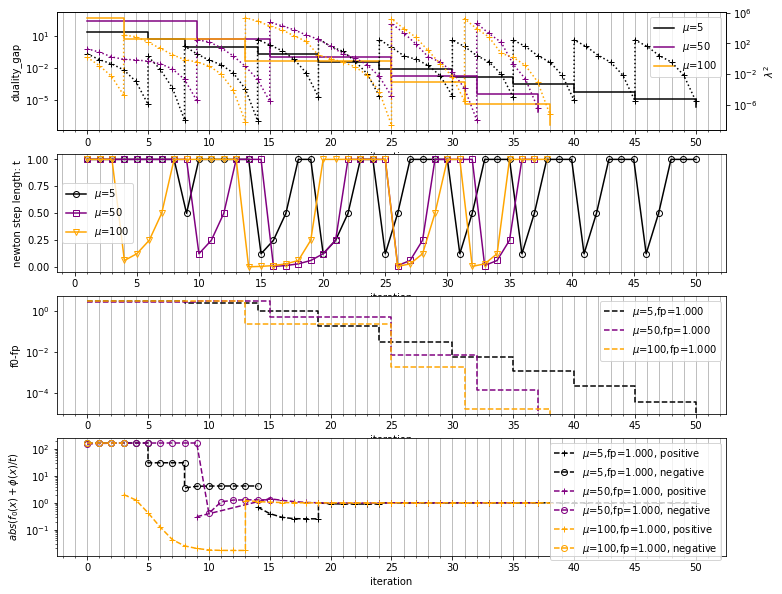

In [14]:
if __name__ == "__main__":
    plot_figure_convergence_SOCP(n=50, p=5, m=50,
                                 mu_s=[5, 50, 100],
                                 seed=4)

Info: dialing 0 in generating model parameters ...
Info: dialing 1 in generating model parameters ...
Info: iteration=0, decrement=18.800689147433044, t=1
Info: iteration=1, decrement=8.13681544291589, t=1
Info: iteration=2, decrement=3.069297871388761, t=1
Info: iteration=3, decrement=2.2486466918789283, t=1
Info: iteration=4, decrement=1.9802072629856307, t=1
Info: iteration=5, decrement=1.1391375410579654, t=1
Info: iteration=6, decrement=0.250980164163911, t=1
Info: iteration=7, decrement=0.007640627511216318, t=1
Info: iteration=0, decrement=97.96135757900886, t=0.5
Info: iteration=1, decrement=0.09244571890137153, t=1
Info: iteration=2, decrement=0.0008658100124455144, t=1
Info: iteration=0, decrement=92.30021534803592, t=0.5
Info: iteration=1, decrement=0.8592272087557491, t=1
Info: iteration=2, decrement=0.11150091195875833, t=1
Info: iteration=3, decrement=0.005078636222265145, t=1
Info: iteration=0, decrement=78.97895485369506, t=0.5
Info: iteration=1, decrement=1.90754185151

Info: iteration=0, decrement=6501.807793643311, t=0.03125
Info: iteration=1, decrement=913.1513428318972, t=0.125
Info: iteration=2, decrement=0.38748421338238725, t=1
Info: iteration=3, decrement=0.016472198340158423, t=1
Info: iteration=4, decrement=4.601824516861003e-05, t=1
Info: iteration=0, decrement=6497.934919902889, t=0.03125
Info: iteration=1, decrement=913.7853552959112, t=0.125
Info: iteration=2, decrement=0.2236400108755267, t=1
Info: iteration=3, decrement=0.00280268470402837, t=1
Info: iteration=0, decrement=18.800689147433044, t=1
Info: iteration=1, decrement=8.13681544291589, t=1
Info: iteration=2, decrement=3.069297871388761, t=1
Info: iteration=3, decrement=2.2486466918789283, t=1
Info: iteration=4, decrement=1.9802072629856307, t=1
Info: iteration=5, decrement=1.1391375410579654, t=1
Info: iteration=6, decrement=0.250980164163911, t=1
Info: iteration=7, decrement=0.007640627511216318, t=1
Info: iteration=0, decrement=341064.1352052089, t=0.0078125
Info: iteration=1,

Info: iteration=7, decrement=0.011333869848932313, t=1
Info: iteration=0, decrement=99.03424866737782, t=0.5
Info: iteration=1, decrement=0.014899887233102638, t=1
Info: iteration=0, decrement=96.46352653865038, t=0.5
Info: iteration=1, decrement=0.17236517375184168, t=1
Info: iteration=2, decrement=0.0022718059780452013, t=1
Info: iteration=0, decrement=88.71986257940218, t=0.5
Info: iteration=1, decrement=0.9251638489983651, t=1
Info: iteration=2, decrement=0.06505455905300202, t=1
Info: iteration=3, decrement=0.0006694795249563857, t=1
Info: iteration=0, decrement=74.15206774367674, t=0.5
Info: iteration=1, decrement=1.501998313072365, t=1
Info: iteration=2, decrement=0.14003560639763818, t=1
Info: iteration=3, decrement=0.0019016052350980914, t=1
Info: iteration=0, decrement=59.98431724539382, t=0.5
Info: iteration=1, decrement=1.20927116815222, t=1
Info: iteration=2, decrement=0.09130193189729804, t=1
Info: iteration=3, decrement=0.0007784422717880756, t=1
Info: iteration=0, decre

Info: iteration=7, decrement=0.011333869848932313, t=1
Info: iteration=0, decrement=344822.5092696942, t=0.0078125
Info: iteration=1, decrement=93917.91771777046, t=0.015625
Info: iteration=2, decrement=20388.042145124393, t=0.03125
Info: iteration=3, decrement=3662.254064625298, t=0.0625
Info: iteration=4, decrement=634.2483383349232, t=0.125
Info: iteration=5, decrement=108.87176979717641, t=0.25
Info: iteration=6, decrement=14.366427548390318, t=1
Info: iteration=7, decrement=4.605393753484322, t=1
Info: iteration=8, decrement=0.8333219333340169, t=1
Info: iteration=9, decrement=0.047381122777997574, t=1
Info: iteration=10, decrement=0.0003151723560138951, t=1
Info: iteration=0, decrement=157212.42195447927, t=0.0078125
Info: iteration=1, decrement=35755.06625898888, t=0.015625
Info: iteration=2, decrement=8198.281398504372, t=0.03125
Info: iteration=3, decrement=1606.2973239818823, t=0.0625
Info: iteration=4, decrement=333.7761027999763, t=0.125
Info: iteration=5, decrement=64.1673

Info: iteration=1, decrement=0.49758581568013094, t=1
Info: iteration=2, decrement=0.06660230926401536, t=1
Info: iteration=3, decrement=0.003329463340138124, t=1
Info: iteration=0, decrement=0.01565537652668239, t=1
Info: iteration=0, decrement=0.06208385134191123, t=1
Info: iteration=1, decrement=2.9310539887759382e-05, t=1
Info: iteration=0, decrement=0.24572265912425376, t=1
Info: iteration=1, decrement=0.00053606392562165, t=1
Info: iteration=0, decrement=0.944776018318536, t=1
Info: iteration=1, decrement=0.010635277466171813, t=1
Info: iteration=0, decrement=3.3382605150982103, t=1
Info: iteration=1, decrement=0.2038298019718094, t=1
Info: iteration=2, decrement=0.003611498617714232, t=1
Info: iteration=0, decrement=9.543180641882017, t=1
Info: iteration=1, decrement=2.4299531087044968, t=1
Info: iteration=2, decrement=0.7861213457494522, t=1
Info: iteration=3, decrement=0.12880617385367593, t=1
Info: iteration=4, decrement=0.004846814141075566, t=1
Info: iteration=0, decrement=

Info: iteration=1, decrement=5.819820448724447, t=1
Info: iteration=2, decrement=0.5854222612934392, t=1
Info: iteration=3, decrement=0.004667219591085756, t=1
Info: iteration=0, decrement=54.41392199034772, t=0.5
Info: iteration=1, decrement=6.482266685915482, t=1
Info: iteration=2, decrement=0.4641515577260422, t=1
Info: iteration=3, decrement=0.03817802515632566, t=1
Info: iteration=4, decrement=0.0008820317929822635, t=1
Info: iteration=0, decrement=62155.87714029869, t=0.0078125
Info: iteration=1, decrement=26531.707150835282, t=0.015625
Info: iteration=2, decrement=5245.970784505786, t=0.03125
Info: iteration=3, decrement=1181.2796125945063, t=0.0625
Info: iteration=4, decrement=396.53975919214975, t=0.125
Info: iteration=5, decrement=40.70180648334882, t=0.25
Info: iteration=6, decrement=5.720421674278726, t=1
Info: iteration=7, decrement=1.8225651918692387, t=1
Info: iteration=8, decrement=0.22916977973319866, t=1
Info: iteration=9, decrement=0.005290855209417493, t=1
Info: ite

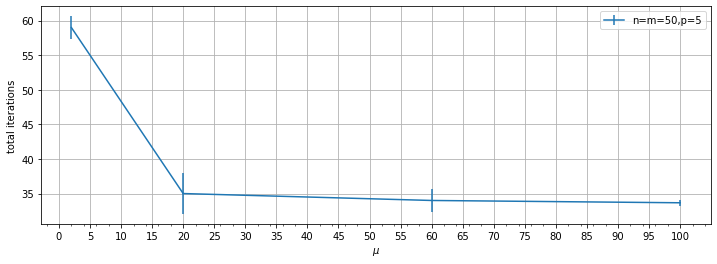

In [15]:
    plot_Newton_iterations_vs_mu(n=50, p=5, m=50,
                                 mu_s=[2 * x for x in range(1, 5, 4)] + [10 * x for x in range(2, 12, 4)],
                                 n_dial=3)
